## ```Whatspp Chat Analysis```

In [15]:
import re
import pandas as pd

In [16]:
with open("bhaichara.txt",'r',encoding='utf-8') as f:
    data = f.read()
print(type(data))

<class 'str'>


In [17]:
pattern = r'\d{1,2}/\d{1,2}/\d{2,4},\s\d{1,2}:\d{2}\s-\s'

In [18]:
messages = re.split(pattern,data)[1:]
# messages
len(messages)

4474

In [19]:
dates = re.findall(pattern,data)
dates

['22/04/25, 12:26 - ',
 '24/12/24, 11:58 - ',
 '24/12/24, 11:58 - ',
 '22/04/25, 12:27 - ',
 '06/04/25, 16:10 - ',
 '22/04/25, 12:27 - ',
 '06/04/25, 16:51 - ',
 '06/04/25, 16:52 - ',
 '06/04/25, 16:52 - ',
 '06/04/25, 16:52 - ',
 '06/04/25, 16:53 - ',
 '06/04/25, 16:53 - ',
 '06/04/25, 16:53 - ',
 '06/04/25, 16:53 - ',
 '22/04/25, 12:27 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:54 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:56 - ',
 '06/04/25, 16:55 - ',
 '06/04/25, 16:56 - ',
 '06/04/25, 16:56 - ',
 '06/04/25, 16:56 - ',
 '22/04/25, 12:27 - ',
 '06/04/25, 18:08 - ',
 '06/04/25, 18:23 - ',
 '06/04/25, 18:23 - ',
 '06/04/25, 18:23 - ',
 '06/04/25, 18:24 - ',
 '06/04/25, 18:23 - ',
 '06/04/25,

```create DataFrame for this data ```

In [20]:
import pandas as pd

df = pd.DataFrame({
    'user_message': messages,
    'message_date': dates
})

# extract only date-time
df['message_date'] = df['message_date'].str.extract(
    r'(^\d{1,2}/\d{1,2}/\d{2},\s\d{1,2}:\d{2})'
)

# convert to datetime
df['message_date'] = pd.to_datetime(
    df['message_date'],
    format="%d/%m/%y, %H:%M"
)

df.rename(columns={'message_date': 'date'}, inplace=True)

df.head()


,user_message,date
0,Messages and calls are end-to-end encrypted. O...,2025-04-22 12:26:00
1,"Group creator created group ""भाईचारा 🇮🇳""\n",2024-12-24 11:58:00
2,+91∙∙∙∙∙∙∙∙76 was added\n,2024-12-24 11:58:00
3,Vishal Pandey was added\n,2025-04-22 12:27:00
4,Vishal Pandey: Kal clg jaa rahe ho kya ?\n,2025-04-06 16:10:00


In [21]:
import re

users = []
messages = []

for message in df['user_message']:
    entry = re.split(r'([\w\W]+?):\s', message)
    
    if entry[1:]:  # if username exists
        users.append(entry[1])
        messages.append(entry[2])
    else:
        users.append('group_notification')
        messages.append(entry[0])

# assign to dataframe
df['user'] = users
df['message'] = messages

# drop old column
df.drop(columns=['user_message'], inplace=True)

df.head()

,date,user,message
0,2025-04-22 12:26:00,group_notification,Messages and calls are end-to-end encrypted. O...
1,2024-12-24 11:58:00,group_notification,"Group creator created group ""भाईचारा 🇮🇳""\n"
2,2024-12-24 11:58:00,group_notification,+91∙∙∙∙∙∙∙∙76 was added\n
3,2025-04-22 12:27:00,group_notification,Vishal Pandey was added\n
4,2025-04-06 16:10:00,Vishal Pandey,Kal clg jaa rahe ho kya ?\n


```Separate  Time Month Year & Date```

In [22]:
df['year'] = df['date'].dt.year
df.head()

,date,user,message,year
0,2025-04-22 12:26:00,group_notification,Messages and calls are end-to-end encrypted. O...,2025
1,2024-12-24 11:58:00,group_notification,"Group creator created group ""भाईचारा 🇮🇳""\n",2024
2,2024-12-24 11:58:00,group_notification,+91∙∙∙∙∙∙∙∙76 was added\n,2024
3,2025-04-22 12:27:00,group_notification,Vishal Pandey was added\n,2025
4,2025-04-06 16:10:00,Vishal Pandey,Kal clg jaa rahe ho kya ?\n,2025


In [23]:
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day'] = df['date'].dt.day
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute

In [24]:
df.head()

,date,user,message,year,month,day,hour,minute
0,2025-04-22 12:26:00,group_notification,Messages and calls are end-to-end encrypted. O...,2025,4,22,12,26
1,2024-12-24 11:58:00,group_notification,"Group creator created group ""भाईचारा 🇮🇳""\n",2024,12,24,11,58
2,2024-12-24 11:58:00,group_notification,+91∙∙∙∙∙∙∙∙76 was added\n,2024,12,24,11,58
3,2025-04-22 12:27:00,group_notification,Vishal Pandey was added\n,2025,4,22,12,27
4,2025-04-06 16:10:00,Vishal Pandey,Kal clg jaa rahe ho kya ?\n,2025,4,6,16,10


In [25]:
words=  []
for message in df['message']:
    words.extend(message.split())

len(words)

19734

In [26]:
# featach media 
df[df['message'] == '<Media omitted>\n'].shape[0]

263

In [27]:
from urlextract import URLExtract

extractor = URLExtract()

links = []

for message in df['message']:
    urls = extractor.find_urls(message)   
    links.extend(urls)                    

print(len(links))

22


## ```Finding the busiest users in the group (only for group chat)```

In [28]:
x  = df['user'].value_counts().head(5)
x

user
Mitansh Kumar    1000
Govind Bhai       794
Sarkar👑           704
Vishal Pandey     460
Radhey sah        438
Name: count, dtype: int64

In [29]:
import matplotlib.pyplot as plt

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Mitansh Kumar'),
  Text(1, 0, 'Govind Bhai'),
  Text(2, 0, 'Sarkar👑'),
  Text(3, 0, 'Vishal Pandey'),
  Text(4, 0, 'Radhey sah')])

c:\Users\manis\anaconda3\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 128081 (\N{CROWN}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
c:\Users\manis\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128081 (\N{CROWN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


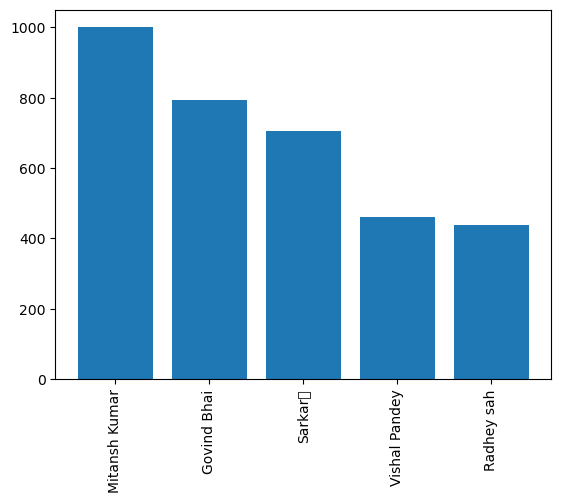

In [30]:
name = x.index
count =  x.values
plt.bar(name,count)
plt.xticks(rotation = 'vertical')

In [31]:
round((df['user'].value_counts()/df.shape[0])*100,2).reset_index().rename(columns={'index':'name','user':'percent'})

,percent,count
0,Mitansh Kumar,22.35
1,Govind Bhai,17.75
2,Sarkar👑,15.74
3,Vishal Pandey,10.28
4,Radhey sah,9.79
5,Abhishek Mishra,9.14
6,Lavkush Clg,6.79
7,CHMBAL KA DAKU,4.69
8,Adarsh CLG,1.92
9,Ayush Rajput {Mosi Ka},0.76


In [32]:
import nltk
nltk.download('stopwords')
import re
from nltk.corpus import stopwords

# english stopwords
stop_words = set(stopwords.words('english'))

# hinglish + hindi custom stopwords
with open('stopword.txt','r')as f:
    hinglish_stopwords = f.read()

stop_words.update(hinglish_stopwords)

# 🔥 your logic
temp_data = df[df['user'] != 'group_notification']
temp_data = temp_data[temp_data['message'] != '<Media omitted>\n']

words = []

for message in temp_data['message']:
    
    # remove punctuation
    message = re.sub(r'[^\w\s]', '', message)
    
    # lowercase + split
    for word in message.lower().split():
        
        # remove stopwords
        if word not in stop_words:
            words.append(word)



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\manis\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [33]:
from collections import Counter
pd.DataFrame(Counter(words).most_common(20))

,0,1
0,shree,2363
1,ram,2360
2,jai,1939
3,ji,681
4,jay,618
5,radhe,520
6,ki,435
7,hai,228
8,message,209
9,bhai,181


- ```REMOVE GROUP MESSAGE```
- ```REMOVE MEDIA OMITTED MESSAGE```
- ```REMOVE STOP  WORDS```

In [34]:
! pip install emoji

In [35]:
import emoji
from collections import Counter
import pandas as pd

emojis = []

for message in df['message']:
    emojis.extend([c for c in message if c in emoji.EMOJI_DATA])

emoji_df = pd.DataFrame(
    Counter(emojis).most_common()
)

emoji_df.head()

,0,1
0,❤,2062
1,🙏,1130
2,🚩,640
3,🦚,245
4,🏻,44


In [36]:
df['month_num'] = df['date'].dt.month
df['month'] = df['date'].dt.month_name()

timeline = df.groupby(['year','month_num','month']).count()['message'].reset_index()

timeline

,year,month_num,month,message
0,2024,12,December,2
1,2025,4,April,288
2,2025,5,May,300
3,2025,6,June,303
4,2025,7,July,357
5,2025,8,August,447
6,2025,9,September,387
7,2025,10,October,387
8,2025,11,November,336
9,2025,12,December,407


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, 'December-2024'),
  Text(1, 0, 'April-2025'),
  Text(2, 0, 'May-2025'),
  Text(3, 0, 'June-2025'),
  Text(4, 0, 'July-2025'),
  Text(5, 0, 'August-2025'),
  Text(6, 0, 'September-2025'),
  Text(7, 0, 'October-2025'),
  Text(8, 0, 'November-2025'),
  Text(9, 0, 'December-2025'),
  Text(10, 0, 'January-2026'),
  Text(11, 0, 'February-2026'),
  Text(12, 0, 'March-2026'),
  Text(13, 0, 'April-2026')])

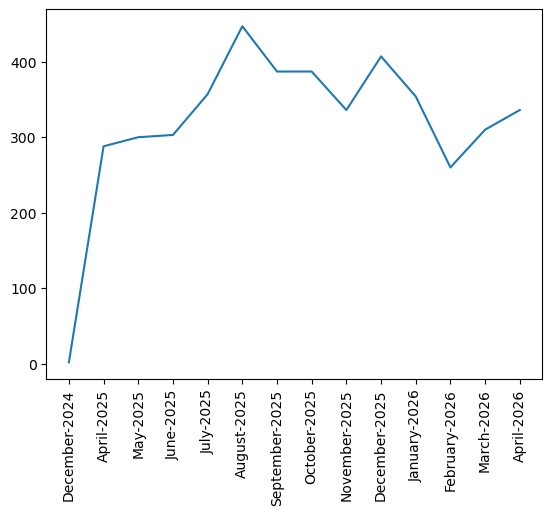

In [37]:
time = []
for i in range(timeline.shape[0]):
    time.append(timeline['month'][i]+ "-"+str(timeline['year'][i]))

timeline['time'] = time

plt.plot(timeline['time'],timeline['message'])
plt.xticks(rotation = 90)

## Date

In [38]:
df['only_date'] = df['date'].dt.date

In [39]:
daily_timeline = df.groupby('only_date').count()['message'].reset_index()
daily_timeline

,only_date,message
0,2024-12-24,2
1,2025-04-06,42
2,2025-04-08,7
3,2025-04-09,6
4,2025-04-10,5
...,...,...
375,2026-04-16,18
376,2026-04-17,10
377,2026-04-18,8
378,2026-04-19,8


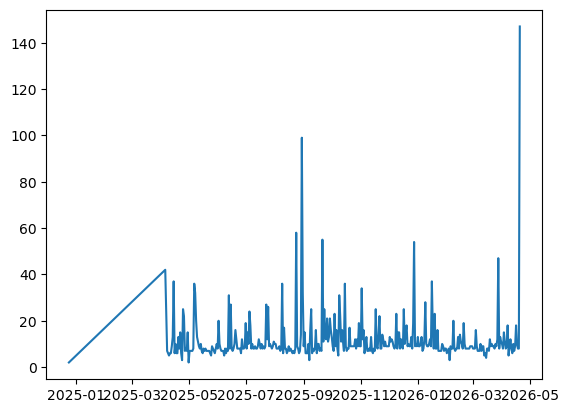

In [40]:
plt.plot(daily_timeline['only_date'],daily_timeline['message'])

In [41]:
df.head()

,date,user,message,year,month,day,hour,minute,month_num,only_date
0,2025-04-22 12:26:00,group_notification,Messages and calls are end-to-end encrypted. O...,2025,April,22,12,26,4,2025-04-22
1,2024-12-24 11:58:00,group_notification,"Group creator created group ""भाईचारा 🇮🇳""\n",2024,December,24,11,58,12,2024-12-24
2,2024-12-24 11:58:00,group_notification,+91∙∙∙∙∙∙∙∙76 was added\n,2024,December,24,11,58,12,2024-12-24
3,2025-04-22 12:27:00,group_notification,Vishal Pandey was added\n,2025,April,22,12,27,4,2025-04-22
4,2025-04-06 16:10:00,Vishal Pandey,Kal clg jaa rahe ho kya ?\n,2025,April,6,16,10,4,2025-04-06


In [42]:
df['day_name']= df['date'].dt.day_name()
df['day_name'].value_counts()

day_name
Sunday       733
Monday       711
Saturday     686
Friday       645
Tuesday      588
Thursday     560
Wednesday    551
Name: count, dtype: int64

In [43]:
df['month'].value_counts()

month
April        624
August       447
December     409
September    387
October      387
July         357
January      354
November     336
March        310
June         303
May          300
February     260
Name: count, dtype: int64

In [47]:
period = []
for hour in df[['day_name','hour']]['hour']:
    if hour == 23:
        period.append(str(hour)+"-"+str('00'))
    elif hour==0:
        period.append(str('00')+'-'+str(hour+1))
    else:
        period.append(str(hour)+"-"+str(hour+1))
        

In [49]:
df['period'] = period
df.head()

,date,user,message,year,month,day,hour,minute,month_num,only_date,day_name,period
0,2025-04-22 12:26:00,group_notification,Messages and calls are end-to-end encrypted. O...,2025,April,22,12,26,4,2025-04-22,Tuesday,12-13
1,2024-12-24 11:58:00,group_notification,"Group creator created group ""भाईचारा 🇮🇳""\n",2024,December,24,11,58,12,2024-12-24,Tuesday,11-12
2,2024-12-24 11:58:00,group_notification,+91∙∙∙∙∙∙∙∙76 was added\n,2024,December,24,11,58,12,2024-12-24,Tuesday,11-12
3,2025-04-22 12:27:00,group_notification,Vishal Pandey was added\n,2025,April,22,12,27,4,2025-04-22,Tuesday,12-13
4,2025-04-06 16:10:00,Vishal Pandey,Kal clg jaa rahe ho kya ?\n,2025,April,6,16,10,4,2025-04-06,Sunday,16-17


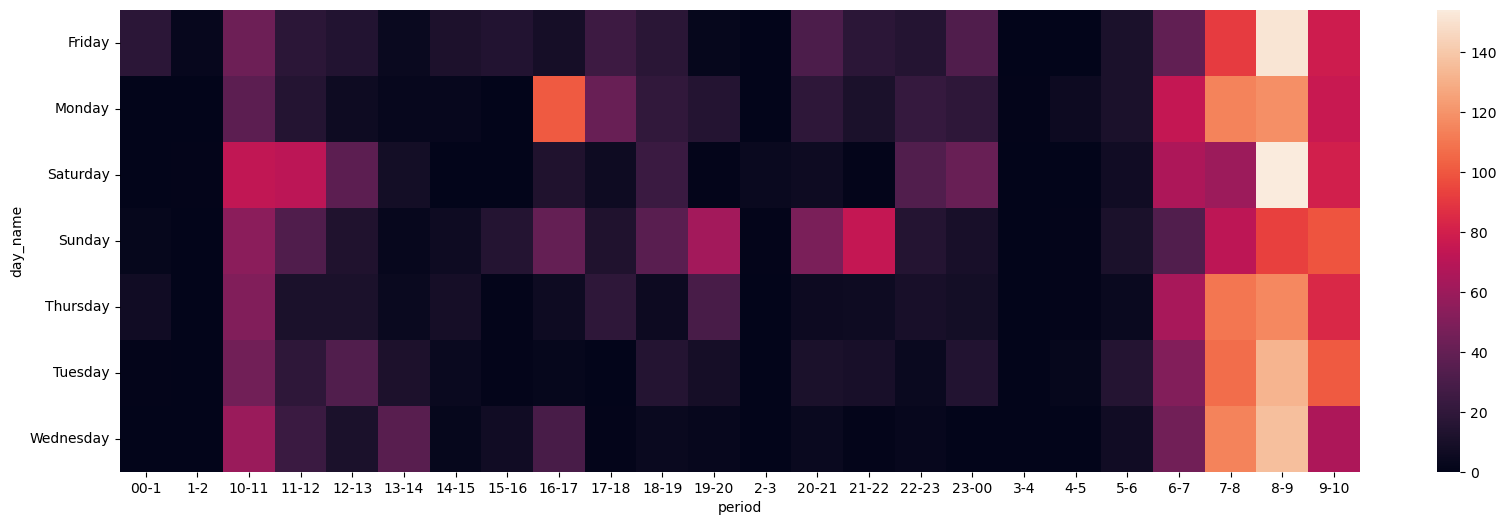

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20,6))

sns.heatmap(
    df.pivot_table(
        index='day_name',
        columns='period',
        values='message',
        aggfunc='count'   # ← yahan comma lagaya
    ).fillna(0)
)

plt.yticks(rotation='horizontal')
plt.show()